# Starter Code — Stereo Vision dengan 1 HP

**Petunjuk persiapan foto, alat, dan hal yang harus dicatat ada di `README.md`.** Notebook ini untuk menjalankan kode dan mengisi hasil. Jalankan **A → G** berurutan.

## A — Konfigurasi dan pemeriksaan file
Nilai sudah diisi sesuai pengukuran: papan **6×10 kotak → 5×9 sudut dalam**, kotak **28 mm**, baseline **8,2 cm (perkiraan, lihat komentar)**.

In [1]:
from pathlib import Path
import os, zipfile, csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

# === ISI SESUAI README ===
# Papan yang dicetak: 6 x 10 kotak -> 5 x 9 sudut dalam (BUKAN 9 x 6).
# Dengan (9, 6) OpenCV salah membaca garis bingkai kertas sebagai sudut (RMS ~11 px).
PATTERN_SIZE = (5, 9)        # sudut dalam (kolom, baris)
SQUARE_SIZE_MM = 28.0        # hasil ukur penggaris: 1 kotak = 2,8 cm
# BASELINE PERKIRAAN (belum diukur langsung):
#   HP digeser dari ujung ke ujung di atas thinwall kotak 500 ml yang diam
#   panjang thinwall ~16,5 cm - lebar HP (Samsung A35 7,8 cm + casing 0,5 cm) ~8,3 cm = ~8,2 cm
BASELINE_CM = 8.2
UPLOAD_ZIP = False           # True hanya di Google Colab
DATA_DIR = Path('praktikum_stereo')

if UPLOAD_ZIP:
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1 or not next(iter(uploaded)).lower().endswith('.zip'):
        raise ValueError('Unggah satu file ZIP folder praktikum_stereo.')
    name = next(iter(uploaded))
    with zipfile.ZipFile(name) as z:
        # Tolak entri yang berpotensi keluar dari direktori kerja
        for m in z.infolist():
            p = Path(m.filename)
            if p.is_absolute() or '..' in p.parts:
                raise ValueError('ZIP mengandung path tidak aman.')
        z.extractall('.')

CAL_DIR = DATA_DIR/'calibration'
STEREO_DIR = DATA_DIR/'stereo'
OUT = DATA_DIR/'output'
OUT.mkdir(parents=True, exist_ok=True)
image_ext = {'.jpg','.jpeg','.png','.bmp'}
cal_files = sorted(p for p in CAL_DIR.iterdir() if p.suffix.lower() in image_ext) if CAL_DIR.exists() else []
L_PATH, R_PATH = STEREO_DIR/'Left obj.jpg', STEREO_DIR/'Right obj.jpg'   # nama file sesuai upload
print('OpenCV:',cv2.__version__)
print('Foto kalibrasi:',len(cal_files),'| kiri:',L_PATH.exists(),'| kanan:',R_PATH.exists())
print('Kotak:',SQUARE_SIZE_MM,'mm | baseline (perkiraan):',BASELINE_CM,'cm')
if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0: raise ValueError('Ukuran kotak dan baseline harus positif.')
if len(cal_files) < 10: raise RuntimeError('Sediakan setidaknya 10 foto kalibrasi (disarankan 15–25).')
if not L_PATH.exists() or not R_PATH.exists(): raise FileNotFoundError('Periksa file foto kiri/kanan di folder stereo/')

OpenCV: 5.1.0
Foto kalibrasi: 24 | kiri: True | kanan: True
Kotak: 28.0 mm | baseline (perkiraan): 8.2 cm


## B — Deteksi sudut chessboard dan ukur jarak dalam piksel
Deteksi dilakukan pada gambar diperkecil (cepat), lalu diperhalus *subpixel* di resolusi penuh. Foto gagal otomatis dilewati.

Foto valid: 23 | Gagal: 1
Foto gagal: ['cal_07.jpg']
Contoh jarak dua sudut dalam piksel: 302.63


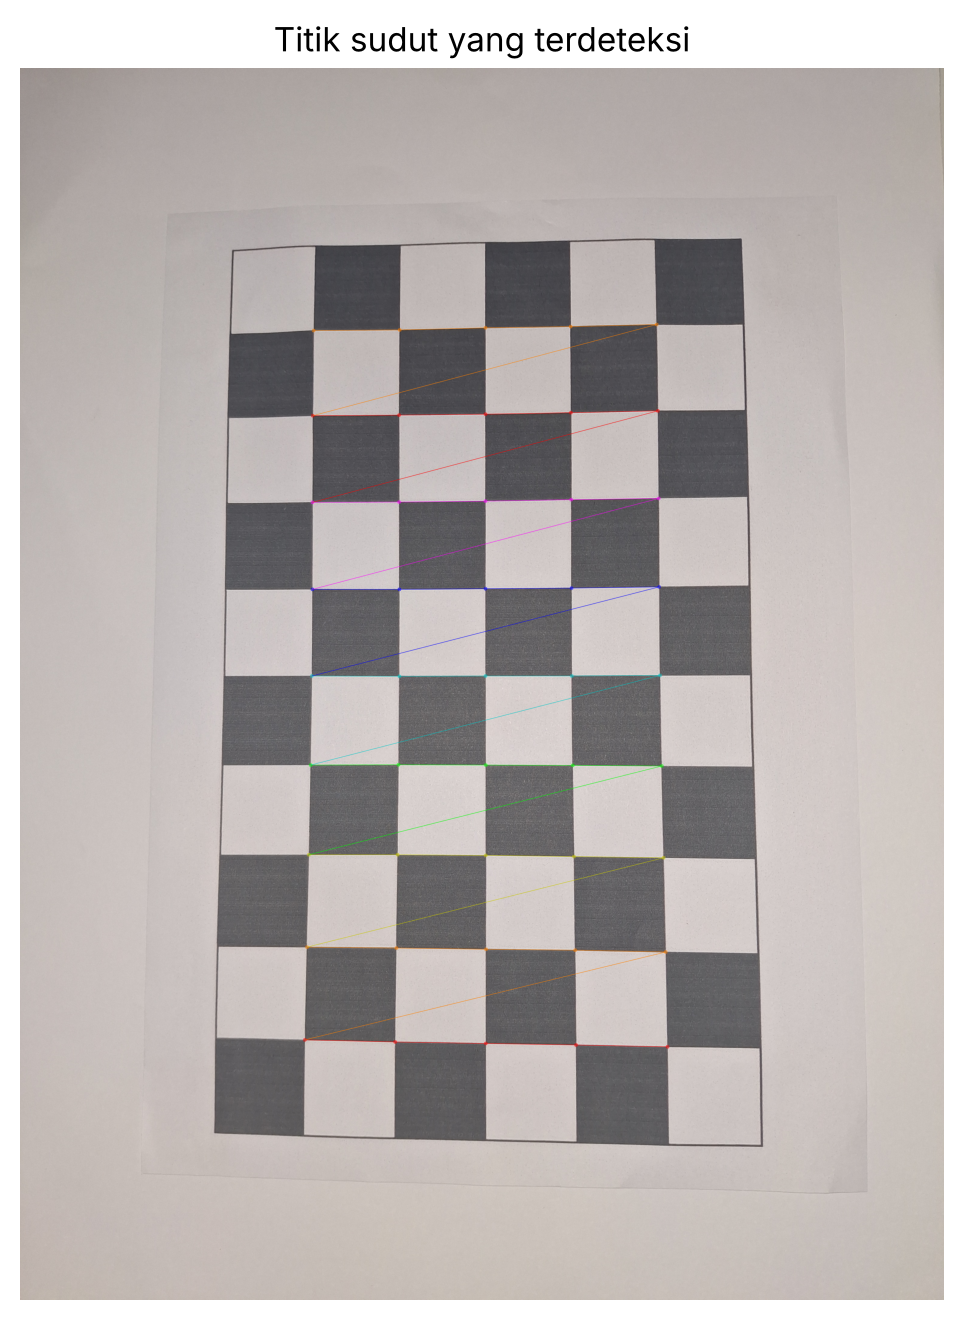

In [2]:
cols, rows = PATTERN_SIZE
obj = np.zeros((cols*rows,3),np.float32)
obj[:,:2] = np.mgrid[0:cols,0:rows].T.reshape(-1,2) * SQUARE_SIZE_MM

def find_corners(gray):
    """1) Deteksi cepat pada gambar diperkecil, lalu perhalus (subpixel) di resolusi penuh.
       2) Jika gagal, coba findChessboardCornersSB (lebih lambat)."""
    scale = 0.25
    small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    flags = cv2.CALIB_CB_ADAPTIVE_THRESH | cv2.CALIB_CB_NORMALIZE_IMAGE
    found, c = cv2.findChessboardCorners(small, PATTERN_SIZE, flags)
    if found:
        c = (c / scale).astype(np.float32)
        c = cv2.cornerSubPix(gray, c, (11,11), (-1,-1),
                             (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 1e-3))
        return True, c.reshape(-1,1,2)
    found, c = cv2.findChessboardCornersSB(gray, PATTERN_SIZE, flags=cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY)
    return found, (c.astype(np.float32).reshape(-1,1,2) if found else None)

objpoints, imgpoints, ok_files, bad_files, spacings = [],[],[],[],[]
size_wh = None
preview = None
for path in cal_files:
    img = cv2.imread(str(path))
    if img is None: bad_files.append(path.name); continue
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    wh = (gray.shape[1],gray.shape[0])
    if size_wh is None: size_wh=wh
    if wh != size_wh:
        bad_files.append(path.name+' (resolusi berbeda)'); continue
    found,corners = find_corners(gray)
    if not found: bad_files.append(path.name); continue
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1,0]-corners[0,0])))
    if preview is None:
        preview=img.copy()
        cv2.drawChessboardCorners(preview,PATTERN_SIZE,corners,True)
print('Foto valid:',len(ok_files),'| Gagal:',len(bad_files))
print('Foto gagal:',bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0],2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(6,8));plt.imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB));plt.title('Titik sudut yang terdeteksi');plt.axis('off');plt.show()
    cv2.imwrite(str(OUT/'corners_preview.jpg'),preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

## C — Kalibrasi kamera: hasil `fx`, `fy`, `cx`, `cy`
Periksa RMS dan simpan hasilnya. **Tidak ada angka focal length asumsi**.

In [3]:
rms,K,dist,rvecs,tvecs=cv2.calibrateCamera(objpoints,imgpoints,size_wh,None,None)
fx,fy,cx,cy = K[0,0],K[1,1],K[0,2],K[1,2]
print('Resolusi kalibrasi:',size_wh)
print('K =\n',K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:',dist.ravel())
# Error per foto: foto dengan error besar bisa dibuang lalu kalibrasi diulang
per_img = []
for name,o,i,r,t in zip(ok_files,objpoints,imgpoints,rvecs,tvecs):
    p,_ = cv2.projectPoints(o,r,t,K,dist)
    per_img.append((name, float(np.sqrt(((p.reshape(-1,2)-i.reshape(-1,2))**2).sum(-1).mean()))))
print('Error per foto (px):', ', '.join(f'{n}={e:.2f}' for n,e in per_img))
np.savez(OUT/'calibration.npz',K=K,dist=dist,image_wh=size_wh,rms=rms,square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS > 2 px. Kemungkinan kertas tidak rata / cetakan tidak persis persegi. '
          'Hasil fx tetap dipakai, tapi dicatat sebagai sumber error.')

Resolusi kalibrasi: (3060, 4080)
K =
 [[2.92691870e+03 0.00000000e+00 1.52051366e+03]
 [0.00000000e+00 2.97782316e+03 2.04233819e+03]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=2926.92 px | fy=2977.82 px | cx=1520.51 px | cy=2042.34 px
RMS reprojection error=3.432 px
Distorsi: [ 2.80631875e-01 -1.21853668e+00  1.23592518e-03 -2.50521753e-03
  1.55045527e+00]
Error per foto (px): cal_01.jpg=2.19, cal_02.jpg=2.12, cal_03.jpg=2.80, cal_04.jpg=2.19, cal_05.jpg=4.62, cal_06.jpg=3.55, cal_08.jpg=3.14, cal_10.jpg=3.80, cal_11.jpg=5.57, cal_12.jpg=2.81, cal_13.jpg=2.35, cal_14.jpg=2.86, cal_15.jpg=2.39, cal_16.jpg=2.48, cal_17.jpg=2.32, cal_18.jpg=3.30, cal_19.jpg=3.02, cal_20.jpg=2.67, cal_21.jpg=3.98, cal_22.jpg=6.74, cal_23.jpg=2.56, cal_24.jpg=3.71, cal_9.jpg=3.48
PERHATIAN: RMS > 2 px. Kemungkinan kertas tidak rata / cetakan tidak persis persegi. Hasil fx tetap dipakai, tapi dicatat sebagai sumber error.


## D — Baca stereo, stereo rectification, dan cek alignment
HP sedikit berputar saat digeser, sehingga koreksi distorsi saja tidak cukup. Sel ini memperkirakan rotasi antar-foto (Essential matrix), lalu melakukan **stereo rectification penuh** dengan `stereoRectify`. Alignment dicek sebelum dan sesudah rectification.

Sebelum rectification: median beda baris = 89.53 px (batas 2 px)
Matching: 482 | Inlier: 343
Perkiraan rotasi HP (derajat, sumbu x/y/z): [ 1.82 -3.05 -1.26] | arah geser: [-0.997  0.017 -0.07 ]
Setelah rectification: median beda baris = 0.68 px | fraksi disparity positif = 100.0%
Focal length setelah rectification f_rect = 3626.3 px (dipakai di rumus Z)
Disparity fitur (px) persentil 5/50/95: [257.6 923.9 943.2]


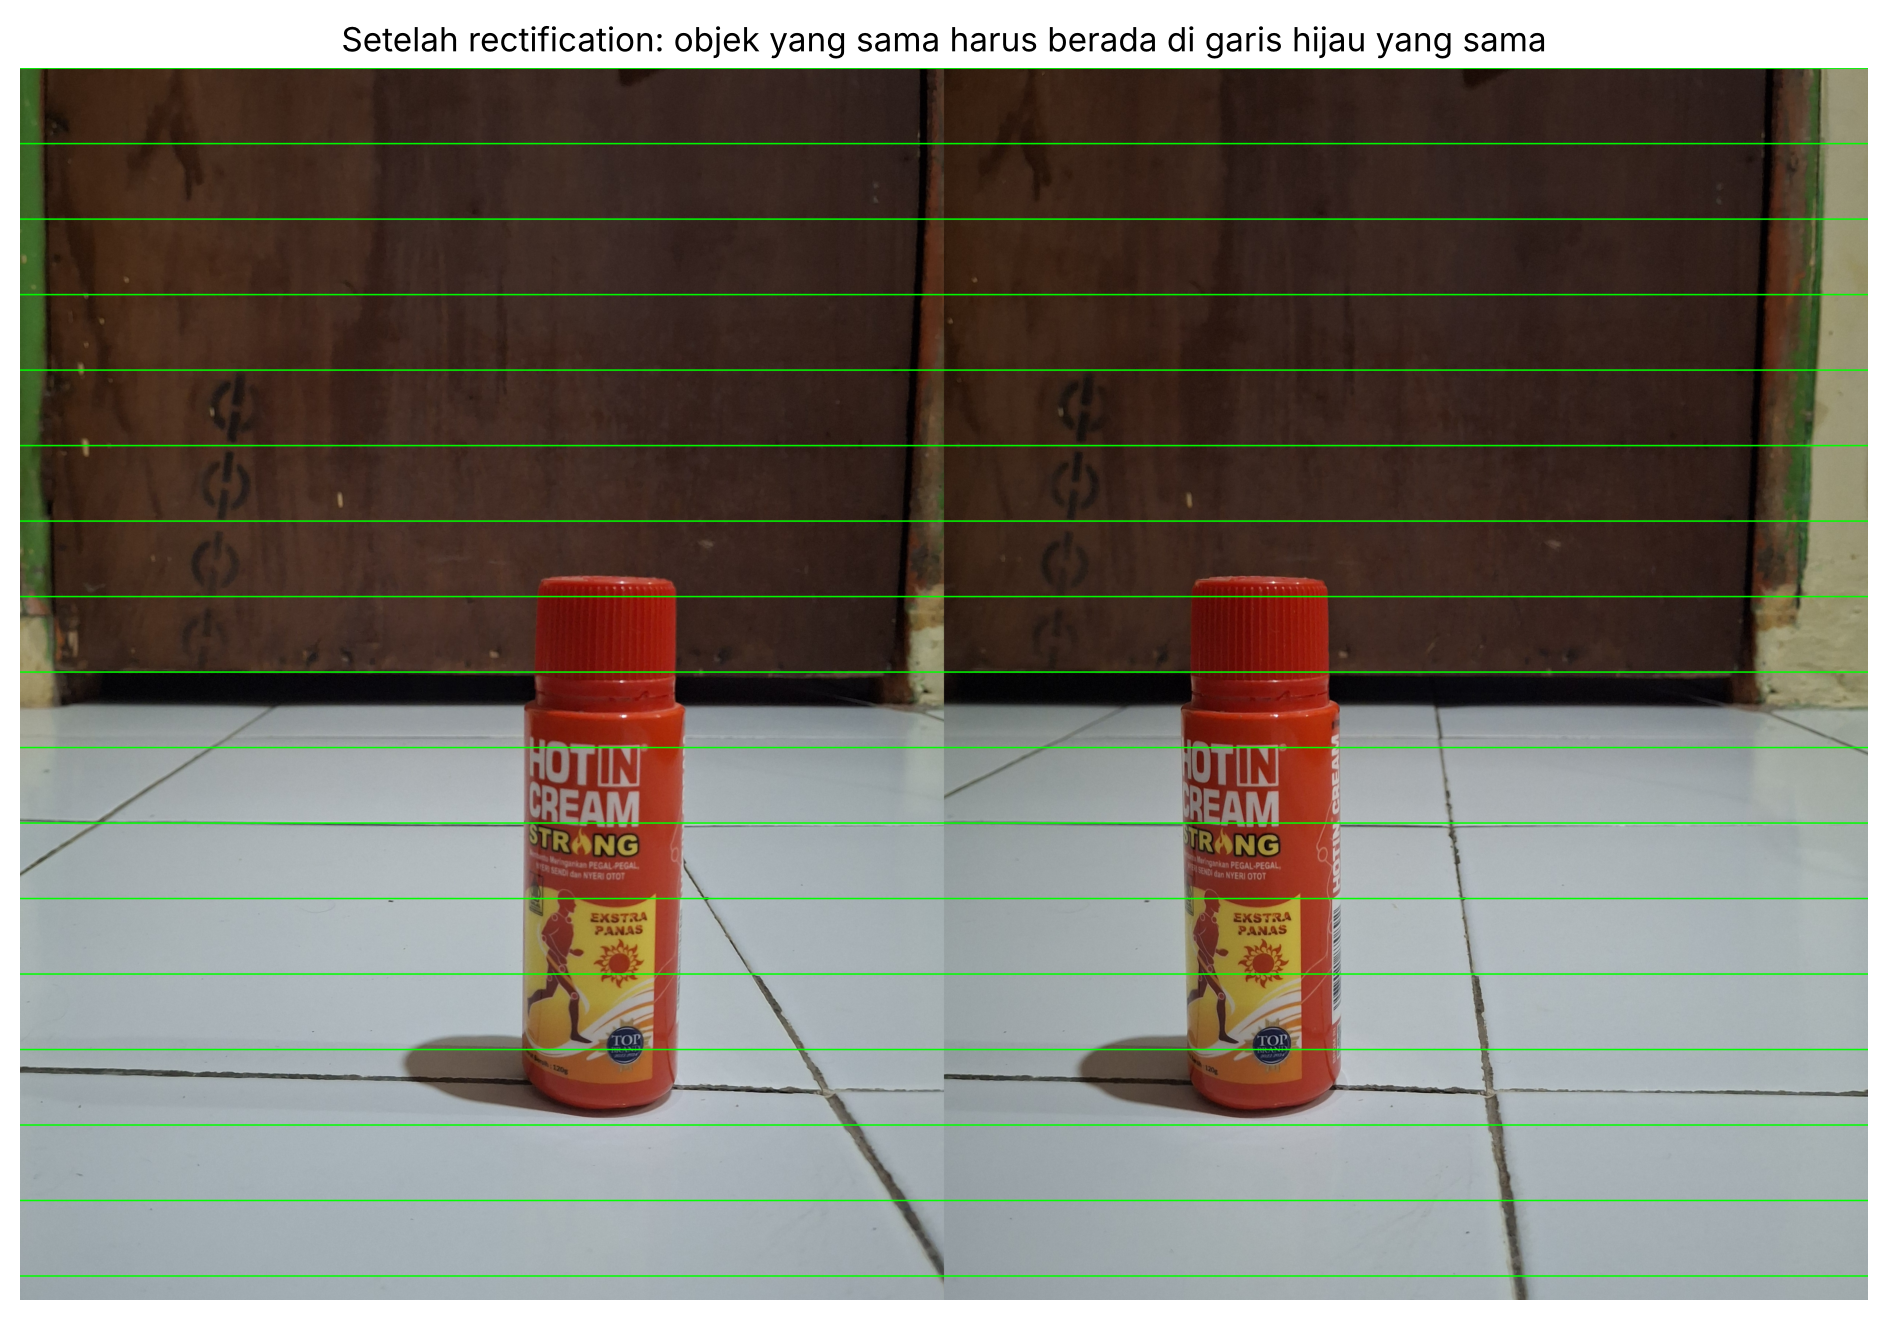

Alignment lolos. Catatan: rotasi diperkirakan dari foto, terutama dari fitur pada botol; jika fitur hanya di satu objek, perkiraan rotasi kurang stabil.


In [4]:
left=cv2.imread(str(L_PATH));right=cv2.imread(str(R_PATH))
if left is None or right is None: raise ValueError('Gagal membaca foto stereo')
if left.shape!=right.shape or (left.shape[1],left.shape[0])!=size_wh:
    raise ValueError('Resolusi stereo harus sama dengan resolusi kalibrasi dan kedua gambar identik.')

# 1) Cocokkan fitur (SIFT lebih stabil daripada ORB untuk foto HP resolusi tinggi)
sift=cv2.SIFT_create(nfeatures=8000)
k1,des1=sift.detectAndCompute(cv2.cvtColor(left,cv2.COLOR_BGR2GRAY),None)
k2,des2=sift.detectAndCompute(cv2.cvtColor(right,cv2.COLOR_BGR2GRAY),None)
if des1 is None or des2 is None: raise RuntimeError('Fitur foto kurang. Gunakan objek/latar bertekstur.')
matches=cv2.BFMatcher().knnMatch(des1,des2,k=2)
good=[a for a,b in matches if a.distance < 0.75*b.distance]
if len(good) < 30: raise RuntimeError('Terlalu sedikit feature match. Ulangi foto dengan lebih banyak tekstur.')
pL=np.float32([k1[m.queryIdx].pt for m in good]);pR=np.float32([k2[m.trainIdx].pt for m in good])
uL=cv2.undistortPoints(pL.reshape(-1,1,2),K,dist,P=K).reshape(-1,2)
uR=cv2.undistortPoints(pR.reshape(-1,1,2),K,dist,P=K).reshape(-1,2)

# 2) Cek alignment SEBELUM rectification (cara starter code asli)
dy_raw=np.abs(uL[:,1]-uR[:,1])
print(f'Sebelum rectification: median beda baris = {np.median(dy_raw):.2f} px (batas 2 px)')

# 3) Perkirakan rotasi HP antar-foto dari Essential matrix, lalu stereo rectification penuh.
#    Arah translasi dari foto; besarnya = BASELINE_CM (hasil ukur/perkiraan).
E,mask=cv2.findEssentialMat(uL,uR,K,cv2.RANSAC,0.999,1.0)
if E is None: raise RuntimeError('Essential matrix gagal dihitung.')
_,R_rel,t_rel,mask=cv2.recoverPose(E,uL,uR,K,mask=mask)
inlier=mask.ravel()>0
if inlier.sum()<30: raise RuntimeError('Inlier kurang dari 30. Ulangi foto.')
rot_deg=np.degrees(cv2.Rodrigues(R_rel)[0].ravel())
print('Matching:',len(good),'| Inlier:',int(inlier.sum()))
print('Perkiraan rotasi HP (derajat, sumbu x/y/z):',np.round(rot_deg,2),'| arah geser:',np.round(t_rel.ravel(),3))
if t_rel[0,0] > 0: raise RuntimeError('Arah geser bukan ke kanan. Periksa apakah foto kiri/kanan tertukar.')
T = t_rel*(BASELINE_CM/100.0)
R1,R2,P1,P2,Q,_,_=cv2.stereoRectify(K,dist,K,dist,size_wh,R_rel,T,alpha=0)
m1x,m1y=cv2.initUndistortRectifyMap(K,dist,R1,P1,size_wh,cv2.CV_32FC1)
m2x,m2y=cv2.initUndistortRectifyMap(K,dist,R2,P2,size_wh,cv2.CV_32FC1)
left_u=cv2.remap(left,m1x,m1y,cv2.INTER_LINEAR)
right_u=cv2.remap(right,m2x,m2y,cv2.INTER_LINEAR)
f_rect=float(P1[0,0])

# 4) Cek alignment SETELAH rectification
rL=cv2.undistortPoints(pL[inlier].reshape(-1,1,2),K,dist,R=R1,P=P1).reshape(-1,2)
rR=cv2.undistortPoints(pR[inlier].reshape(-1,1,2),K,dist,R=R2,P=P2).reshape(-1,2)
dy=np.abs(rL[:,1]-rR[:,1]);dx=rL[:,0]-rR[:,0]
median_dy=float(np.median(dy));positive_fraction=float(np.mean(dx>0))
print(f'Setelah rectification: median beda baris = {median_dy:.2f} px | fraksi disparity positif = {positive_fraction:.1%}')
print(f'Focal length setelah rectification f_rect = {f_rect:.1f} px (dipakai di rumus Z)')
print('Disparity fitur (px) persentil 5/50/95:',np.round(np.percentile(dx,[5,50,95]),1))

vis=np.hstack([left_u,right_u]).copy()
for y in range(0,vis.shape[0],250): cv2.line(vis,(0,y),(vis.shape[1],y),(0,255,0),4)
plt.figure(figsize=(12,8));plt.imshow(cv2.cvtColor(vis,cv2.COLOR_BGR2RGB));plt.title('Setelah rectification: objek yang sama harus berada di garis hijau yang sama');plt.axis('off');plt.show()
cv2.imwrite(str(OUT/'rectified_pair.jpg'),cv2.resize(vis,None,fx=0.5,fy=0.5))
ALIGNMENT_OK = (median_dy<=2.0 and positive_fraction>=0.70)
if not ALIGNMENT_OK:
    raise RuntimeError('Alignment belum cukup baik setelah rectification. Ulangi foto stereo; jangan pakai hasil depth.')
print('Alignment lolos. Catatan: rotasi diperkirakan dari foto, terutama dari fitur pada botol; '
      'jika fitur hanya di satu objek, perkiraan rotasi kurang stabil.')

## E — Hitung disparity dan depth map
Foto 12 MP menghasilkan disparity ratusan piksel, sehingga SGBM dihitung pada gambar ×0,25 dengan rentang disparity otomatis. Rumus: `Z = f_rect × B / d` (f_rect = focal length setelah rectification).

minDisparity=32 | numDisparities=224 (pada skala 0.25)
Piksel disparity valid: 45.9% (area polos seperti lantai/pintu biasanya tidak valid)


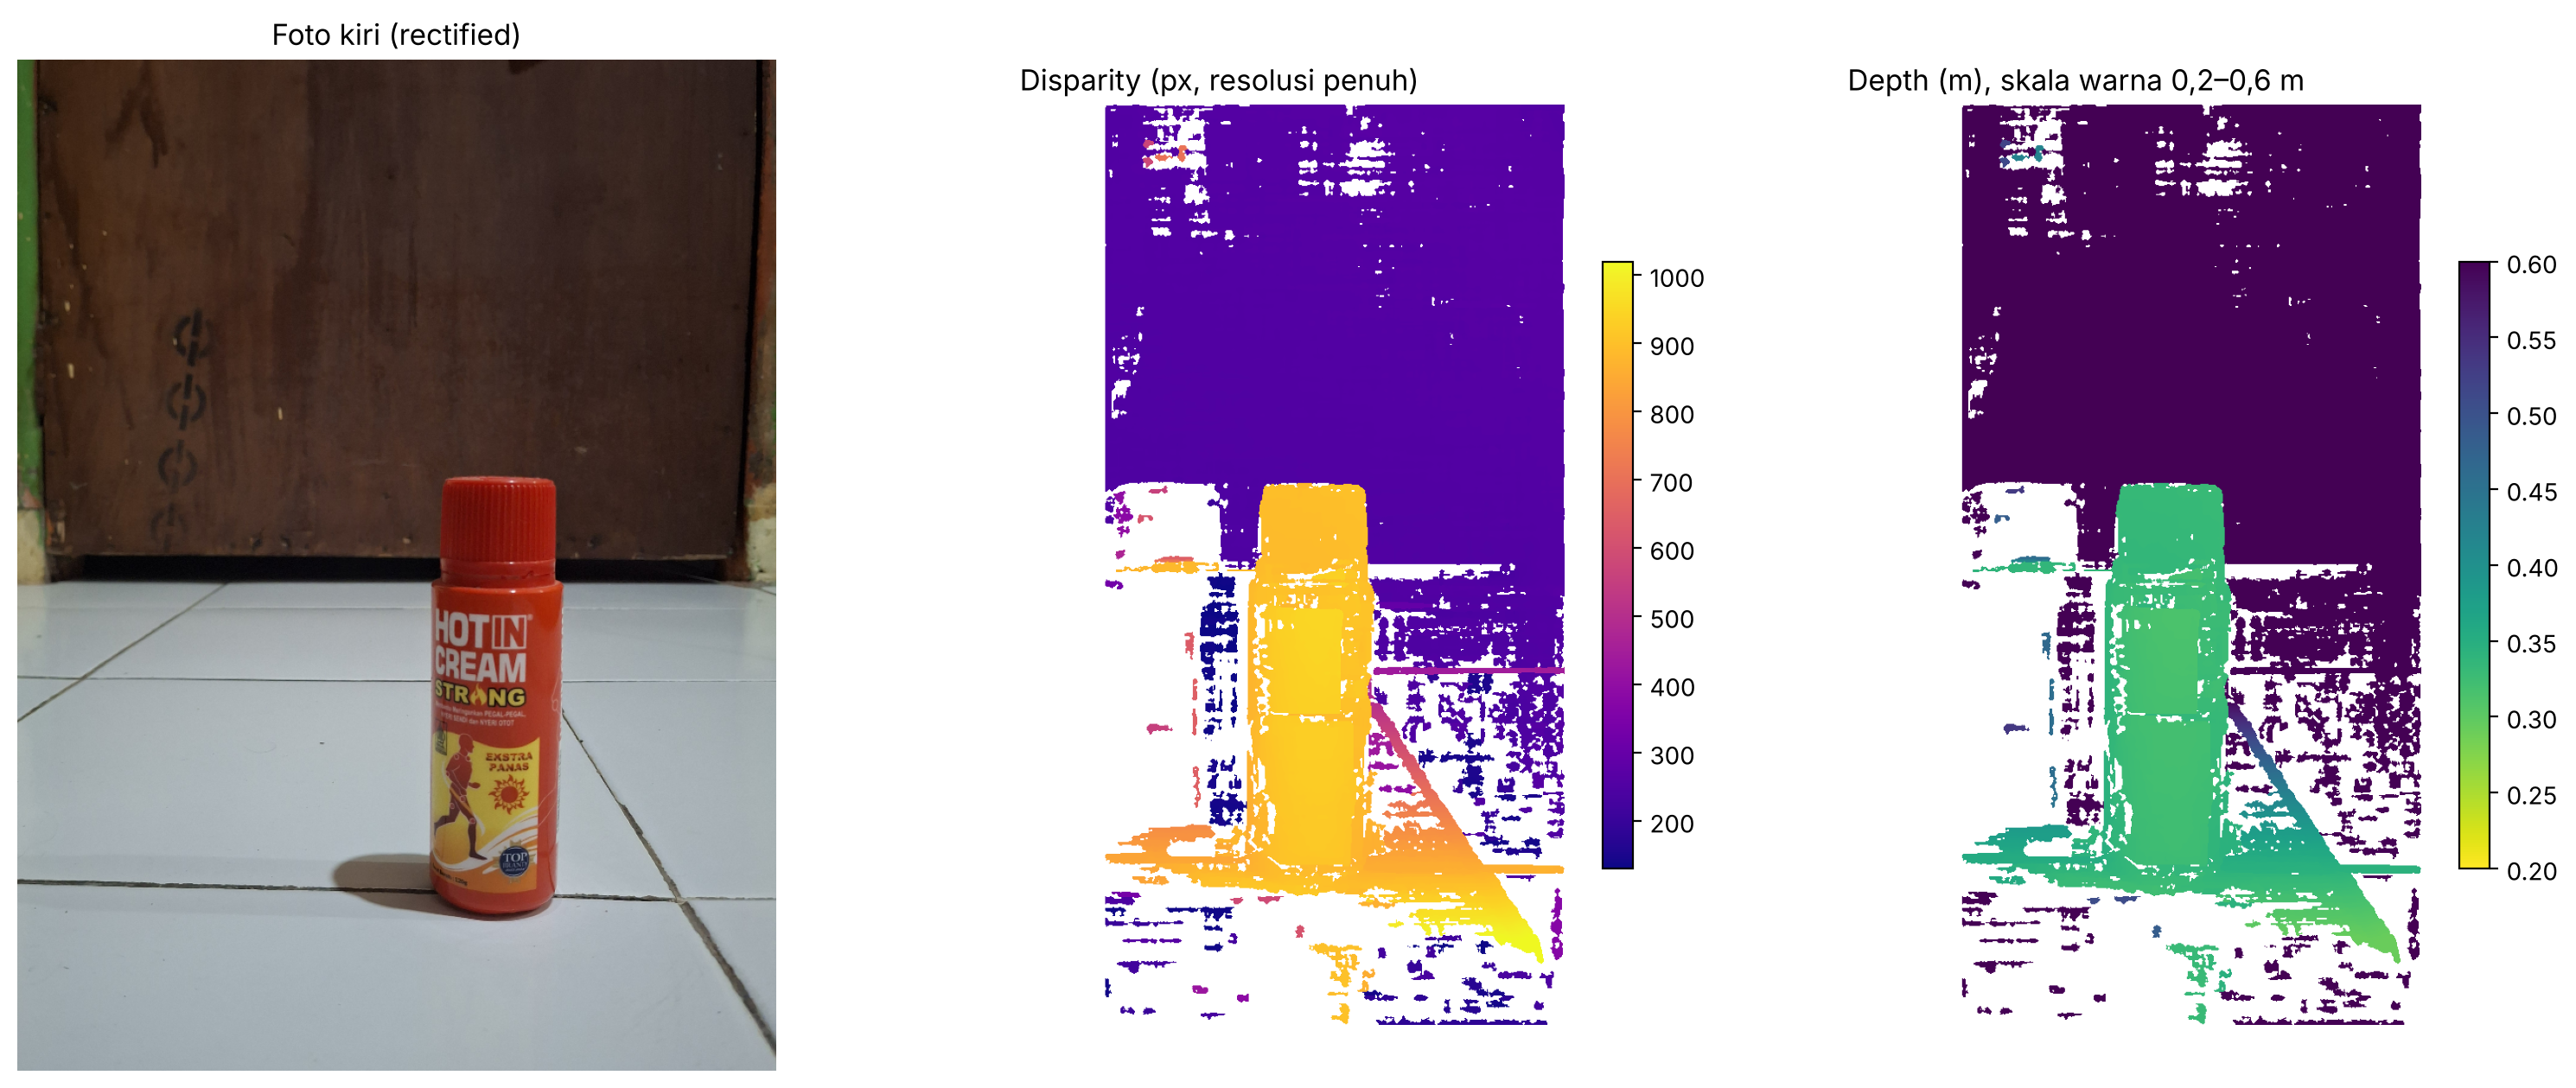

True

In [5]:
if not ALIGNMENT_OK: raise RuntimeError('Alignment belum lolos.')
# Foto 12 MP -> disparity bisa ~900 px. SGBM dihitung pada gambar diperkecil supaya cepat,
# lalu disparity dikembalikan ke skala resolusi penuh.
SCALE = 0.25
SGBM_BLOCK_SIZE = 7
lg=cv2.resize(cv2.cvtColor(left_u,cv2.COLOR_BGR2GRAY),None,fx=SCALE,fy=SCALE,interpolation=cv2.INTER_AREA)
rg=cv2.resize(cv2.cvtColor(right_u,cv2.COLOR_BGR2GRAY),None,fx=SCALE,fy=SCALE,interpolation=cv2.INTER_AREA)
# Rentang disparity otomatis dari feature match (kelipatan 16)
d_lo,d_hi=np.percentile(dx,[2,98])*SCALE
MIN_DISP=max(0,int(np.floor(d_lo/16)-1)*16)
NUM_DISP=int(np.ceil((d_hi-MIN_DISP)/16)+1)*16
print(f'minDisparity={MIN_DISP} | numDisparities={NUM_DISP} (pada skala {SCALE})')
sgbm=cv2.StereoSGBM_create(
    minDisparity=MIN_DISP, numDisparities=NUM_DISP,
    blockSize=SGBM_BLOCK_SIZE,
    P1=8*1*SGBM_BLOCK_SIZE**2, P2=32*1*SGBM_BLOCK_SIZE**2,
    uniquenessRatio=10, speckleWindowSize=70, speckleRange=2,
    disp12MaxDiff=1, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
raw=sgbm.compute(lg,rg).astype(np.float32)/16.0
valid_s=raw>=MIN_DISP+0.5
disp=np.full(raw.shape,np.nan,np.float32);disp[valid_s]=raw[valid_s]/SCALE   # px resolusi penuh
valid=np.isfinite(disp)
Z=np.full(disp.shape,np.nan,np.float32)
Z[valid]=(f_rect*(BASELINE_CM/100.0))/disp[valid]
print(f'Piksel disparity valid: {valid.mean()*100:.1f}% (area polos seperti lantai/pintu biasanya tidak valid)')
small_left=cv2.resize(left_u,(disp.shape[1],disp.shape[0]))
fig,ax=plt.subplots(1,3,figsize=(15,7))
ax[0].imshow(cv2.cvtColor(small_left,cv2.COLOR_BGR2RGB));ax[0].set_title('Foto kiri (rectified)')
a=ax[1].imshow(np.ma.masked_invalid(disp),cmap='plasma');ax[1].set_title('Disparity (px, resolusi penuh)');fig.colorbar(a,ax=ax[1],fraction=.04)
b=ax[2].imshow(np.ma.masked_invalid(Z),cmap='viridis_r',vmin=0.2,vmax=0.6);ax[2].set_title('Depth (m), skala warna 0,2–0,6 m');fig.colorbar(b,ax=ax[2],fraction=.04)
for x in ax:x.axis('off')
plt.tight_layout();plt.savefig(OUT/'disparity_depth.png',dpi=100);plt.show()
np.save(OUT/'disparity_px.npy',disp)
np.save(OUT/'depth_m.npy',Z)
cv2.imwrite(str(OUT/'left_rectified.jpg'),left_u)

## F — Ukur satu objek pada ROI
ROI otomatis di pusat fitur yang cocok (botol). Bisa diganti manual dengan `ROI_X`, `ROI_Y` (koordinat foto kiri rectified, resolusi penuh).

ROI pusat=(1973,2823) px | piksel valid=100%
disparity ROI=932.00 px | Z estimasi=0.319 m | meteran=0.300 m | error=6.35%
  jika baseline 7.2 cm -> Z = 0.280 m
  jika baseline 8.2 cm -> Z = 0.319 m
  jika baseline 9.2 cm -> Z = 0.358 m


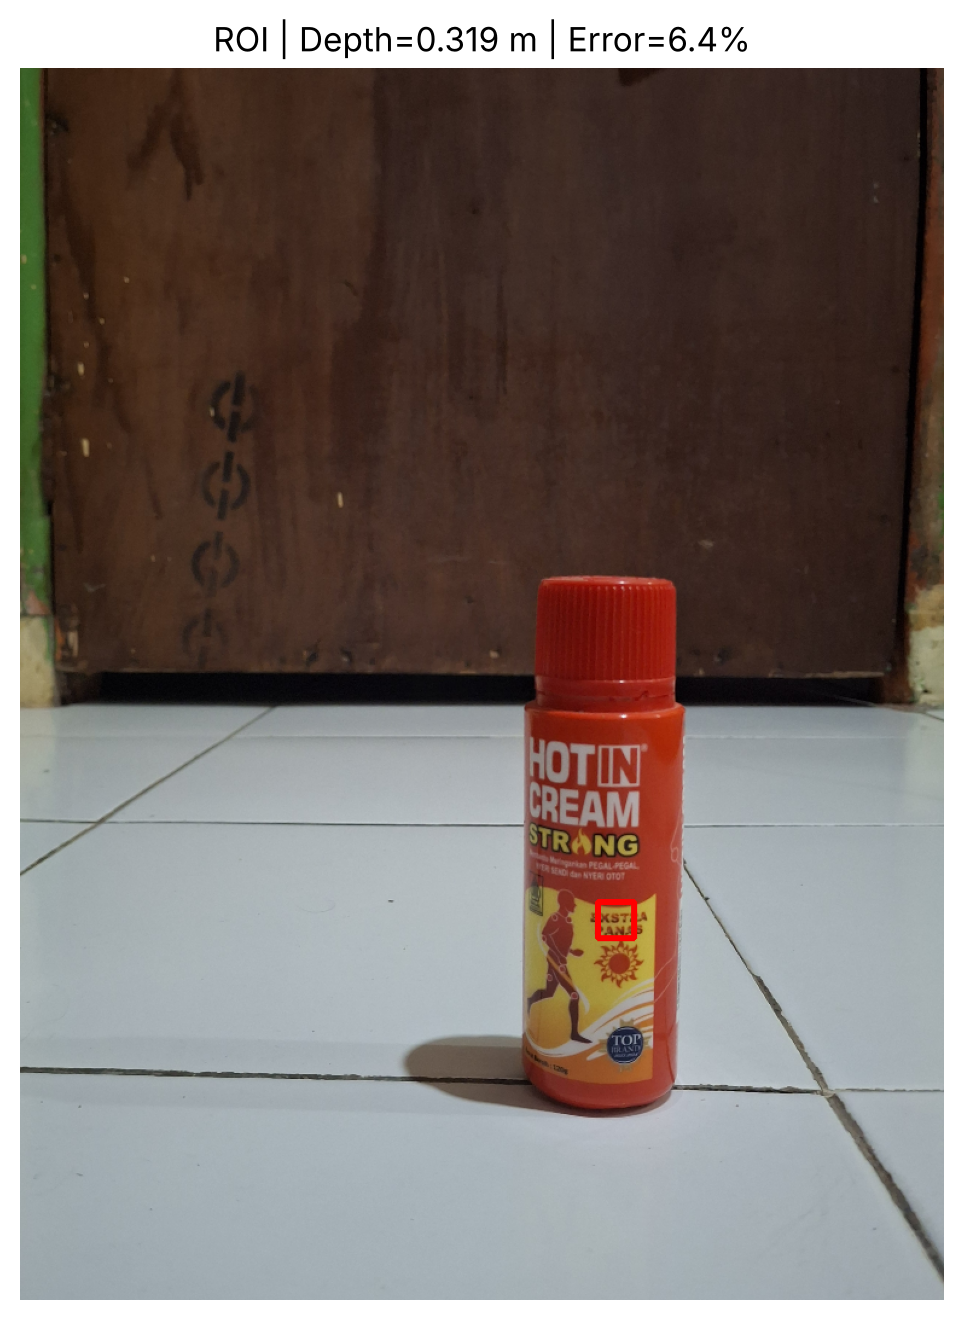

In [6]:
# === ISI HASIL PENGAMATAN ===
# Koordinat ROI pada foto kiri RECTIFIED resolusi penuh (lihat gambar di sel D/E).
# None = otomatis: pusat fitur yang cocok (biasanya objek utama).
ROI_X = None
ROI_Y = None
ROI_RADIUS = 60        # jendela 121 x 121 piksel resolusi penuh
Z_TRUE_M = 0.30        # jarak HP -> botol menurut meteran (30 cm)

if ROI_X is None or ROI_Y is None:
    ROI_X,ROI_Y=int(np.median(rL[:,0])),int(np.median(rL[:,1]))
# Peta disparity/depth berada di skala SCALE
sx,sy,sr=int(ROI_X*SCALE),int(ROI_Y*SCALE),max(2,int(ROI_RADIUS*SCALE))
h,w=Z.shape
if not (0<=sx<w and 0<=sy<h):raise ValueError('ROI berada di luar gambar.')
x0,x1=max(0,sx-sr),min(w,sx+sr+1)
y0,y1=max(0,sy-sr),min(h,sy+sr+1)
roi_z=Z[y0:y1,x0:x1];roi_d=disp[y0:y1,x0:x1]
mask_roi=np.isfinite(roi_z)&(roi_z>0)
if mask_roi.sum()<10:raise RuntimeError('ROI memiliki <10 piksel depth valid. Pilih area lain.')
Z_EST=float(np.median(roi_z[mask_roi]))
D_MED=float(np.median(roi_d[mask_roi]))
if Z_TRUE_M<=0:raise ValueError('Jarak meteran harus positif.')
ERROR_PCT=abs(Z_EST-Z_TRUE_M)/Z_TRUE_M*100
print(f'ROI pusat=({ROI_X},{ROI_Y}) px | piksel valid={mask_roi.mean():.0%}')
print(f'disparity ROI={D_MED:.2f} px | Z estimasi={Z_EST:.3f} m | meteran={Z_TRUE_M:.3f} m | error={ERROR_PCT:.2f}%')
# Sensitivitas terhadap baseline (karena baseline masih perkiraan)
for b in (BASELINE_CM-1, BASELINE_CM, BASELINE_CM+1):
    print(f'  jika baseline {b:.1f} cm -> Z = {f_rect*b/100/D_MED:.3f} m')
shown=cv2.cvtColor(small_left,cv2.COLOR_BGR2RGB).copy()
cv2.rectangle(shown,(x0,y0),(x1-1,y1-1),(255,0,0),3)
plt.figure(figsize=(6,8));plt.imshow(shown);plt.title(f'ROI | Depth={Z_EST:.3f} m | Error={ERROR_PCT:.1f}%');plt.axis('off')
plt.savefig(OUT/'roi.png',dpi=100);plt.show()

## G — Simpan satu baris percobaan
Jalankan setiap kali mengukur jarak baru. **Sebelum uji berikutnya:** ganti foto `left.jpg/right.jpg`, lalu ulangi **D → G**. Jangan mengulang C bila parameter kamera tetap.

In [7]:
TEST_ID = 'uji_01_030cm'  # GANTI untuk setiap jarak
csv_path=OUT/'hasil_pengukuran.csv'
record={
    'uji':TEST_ID,'baseline_cm':BASELINE_CM,'baseline_status':'perkiraan','square_size_mm':SQUARE_SIZE_MM,
    'fx_px':round(float(fx),3),'fy_px':round(float(fy),3),'f_rect_px':round(f_rect,3),
    'rms_px':round(float(rms),3),'median_vertical_error_px':round(median_dy,3),
    'disparity_roi_px':round(D_MED,3),'depth_est_m':round(Z_EST,4),
    'depth_meter_m':round(Z_TRUE_M,4),'error_pct':round(ERROR_PCT,2)}
rows=[]
if csv_path.exists():
    with csv_path.open(encoding='utf-8',newline='') as fh:rows=list(csv.DictReader(fh))
rows=[r for r in rows if r['uji']!=TEST_ID]+[record]
with csv_path.open('w',encoding='utf-8',newline='') as fh:
    writer=csv.DictWriter(fh,fieldnames=list(record),extrasaction='ignore');writer.writeheader();writer.writerows(rows)
print('Tersimpan:',csv_path)
for r in rows:print(r['uji'],'| jarak meteran',r['depth_meter_m'],'m | estimasi',r['depth_est_m'],'m | error',r['error_pct'],'%')

Tersimpan: praktikum_stereo/output/hasil_pengukuran.csv
uji_01_030cm | jarak meteran 0.3 m | estimasi 0.3191 m | error 6.35 %


## Tugas analisis dan flowchart
**Ikuti format pengumpulan di README bagian 8.** Buat sendiri dua flowchart: (1) **A→B→C** dengan keputusan berhasil/gagal mendeteksi sudut; (2) **D→E→F→G** dengan keputusan alignment/ROI valid. Bandingkan minimal tiga jarak dan tulis penyebab error.

**Batasan:** proses ini menggunakan pendekatan translasi horizontal murni. Pemeriksaan alignment saja **tidak membuktikan** seluruh asumsi geometri terpenuhi; jangan melaporkan hasil sebagai jarak metrik terverifikasi tanpa perbandingan meteran.